In [88]:
# coding=utf-8
import numpy as np
import pandas as pd
import seaborn as sns
from time import time
from operator import add
from functools import reduce
import tqdm
import matplotlib.pyplot as plt
from numpy.random import uniform
from lib.bandits import Bernoulli, Gaussian
from lib.policies import p_auer, p_ape, p_unif
K = 10
D = 2
numiter = 2000
seeds = (np.random.uniform(size=numiter)*2**31).astype(np.uint)
m = K
delta = 0.1
eps_1 = 0.05
eps_2 = 0.

In [89]:
res_ape_k = [[] for _ in range(5)]
res_auer_k = [[] for _ in range(5)]
for i in tqdm.trange(numiter):
    means = np.random.uniform(size=(K, D))
    bandit = Bernoulli(means)
    #if bandit.H>5000: continue
    psi_ape = p_ape(bandit)
    psi_auer = p_auer(bandit)
    for j in range(5):
       res_ape_k[j]+=[sum(psi_ape.loop(i, delta, eps_1, eps_2, j+1)[0][1])]
       res_auer_k[j]+=[sum(psi_auer.loop(i, delta, eps_1, j+1)[0][1])]
res_auer_k = np.array(res_auer_k)
res_ape_k = np.array(res_ape_k)

100%|██████████| 2000/2000 [00:00<00:00, 36094.63it/s]


In [78]:
res_auer_k.mean(-1) / res_ape_k.mean(-1)

array([2.59440158, 1.96255797, 1.67134466, 1.52871765, 1.44075579])

In [80]:
d = {'x': reduce(add, [[f"k=%d"%k]*numiter for k in range(1, 6) ]*2),
     'y': np.concatenate((*res_ape_k[:5], *res_auer_k[:5])),
     'Algorithm': [r"$\varepsilon_1$-APE-$k$"]*K*numiter + [r"Heuristic-PSI-Unif-Elim"]*K*numiter }
df = pd.DataFrame(data=d)

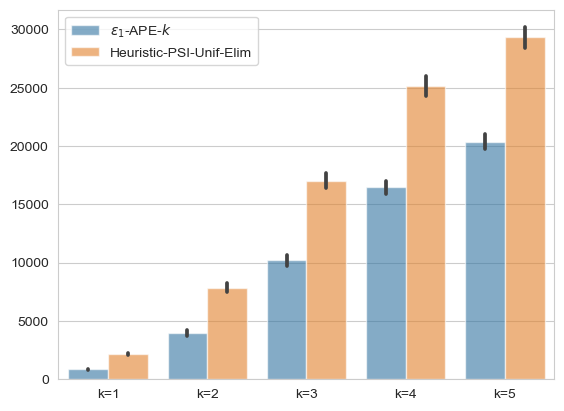

In [82]:
g = sns.barplot(
    data=df,
    x="x", y="y", hue="Algorithm", palette="tab10", alpha=0.6,
)

g.set(
    xlabel='',
    ylabel=''
)
#g.legend_.remove()
g.legend_.set_title("")